In [1]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive', force_remount=True)

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"

PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xskillscore
import numpy as np
import string

sys.path.insert(1, str(ROOT / "src"))

from statistical_downscaling.evaluation.metrics.univariate.marginals import (
    rel_error_dry_days, rel_error_wet_mean, rel_error_std, rel_error_p99
)
from statistical_downscaling.evaluation.metrics.univariate.temporal import corr

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages


/content/drive/MyDrive/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
models = ["BerGamma", "DDPM", "FlowMatch"]
preds_models = { m: xr.open_dataset( next( f for f in (PREDS_ROOT / m).glob("*.nc") if f.is_file() ))
    for m in models
}

ds_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)

In [17]:
corr_f = lambda x, y: corr(x, y, deseasonal=True, corr_type="spearman")

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]

def compute_metrics(target, preds: dict, metrics: dict, member_dim="member") -> xr.Dataset:
    out = {}
    for name, f in metrics.items():
        per_model = []
        for m, p in preds.items():
            r = f(p, target)
            if member_dim in r.dims:
                r = r.mean(member_dim)
            per_model.append(r.drop_vars([c for c in r.coords if c not in r.dims], errors="ignore"))
        out[name] = xr.concat(per_model, dim="model", join="inner").assign_coords(model=list(preds))
    return xr.Dataset(out)


def _ref_value(name):
    return 1.0 if "corr" in name.lower() else 0.0


def plot_metrics_violin(ds, metrics=None, labels=None, colors=None, ncols=3, axes=None):
    metrics = list(metrics or ds.data_vars)
    labels, colors = labels or {}, colors or {}
    models = ds.model.values.tolist()
    if axes is None:
        nrows = -(-len(metrics) // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows),
                                 squeeze=False, constrained_layout=True, sharex=True)
        for ax in axes.ravel()[len(metrics):]:
            ax.set_visible(False)
    axes = np.ravel(axes)

    for ax, name in zip(axes, metrics):
        data = [ds[name].sel(model=m).values.ravel() for m in models]
        data = [d[np.isfinite(d)] for d in data]
        pos = np.arange(len(models))
        vp = ax.violinplot(data, positions=pos, showmedians=True, showextrema=False, widths=0.8)
        for i, body in enumerate(vp["bodies"]):
            c = colors.get(models[i], SERIES_COLORS[i % len(SERIES_COLORS)])
            c = "#eda100"
            body.set_facecolor(c); body.set_edgecolor(c); body.set_alpha(0.55)
        vp["cmedians"].set_color("#222221"); vp["cmedians"].set_linewidth(1.5)
        ax.axhline(_ref_value(name), color="0.4", lw=1, ls="--", zorder=0)
        ax.set_xticks(pos, models, rotation=90, ha="right")
        ax.set_title(labels.get(name, name), fontsize=10)
        ax.grid(axis="y", alpha=0.25, lw=0.5)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        if "rel" in name:
            ax.set_ylim(-40,40)
            ax.set_ylabel("%")
    return fig, axes


def plot_metrics_maps(ds, metrics=None, labels=None, pct=98, x="lon", y="lat", **plot_kw):
    metrics = list(metrics or ds.data_vars)
    labels = labels or {}
    models = ds.model.values.tolist()
    fig, axes = plt.subplots(len(metrics), len(models), figsize=(3.1 * len(models), 2.8 * len(metrics)), squeeze=False, sharex=True, sharey=True,
                             subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
    for i, name in enumerate(metrics):
        da = ds[name]
        if "corr" in name.lower():
            kw, extend = dict(cmap="Reds", vmin=0, vmax=1), "min"
        else:
            v = float(np.nanpercentile(np.abs(da.values), pct))
            kw, extend = dict(cmap="BrBG", vmin=-40, vmax=40), "both"
        for j, m in enumerate(models):
            ax = axes[i, j]
            im = da.sel(model=m).plot.contourf(ax=ax, x=x, y=y, transform=ccrs.PlateCarree(),
                                               add_colorbar=False, **kw, **plot_kw)
            ax.coastlines()
            ax.add_feature(cfeature.BORDERS, linewidth=0.5)
            ax.set_title(m if i == 0 else "", fontsize=10)
            ax.set_xlabel(x if i == len(metrics) - 1 else "")
            ax.set_ylabel(y if j == 0 else "")
        fig.colorbar(im, ax=axes[i, :], shrink=0.9, extend=extend, label=labels.get(name, name))
    return fig, axes

In [19]:
metrics = {
    # "rel_error_dry_days": rel_error_dry_days,
    # "rel_error_wet_mean": rel_error_wet_mean,
    # "rel_error_std": rel_error_std,
    # "rel_error_p99": rel_error_p99,
    "corr": corr_f,
}
ds_metrics = compute_metrics(ds_y_test[VAR_DS],
                             {m: d[VAR_DS].mean(dim="member") for m, d in preds_models.items()},
                             metrics)

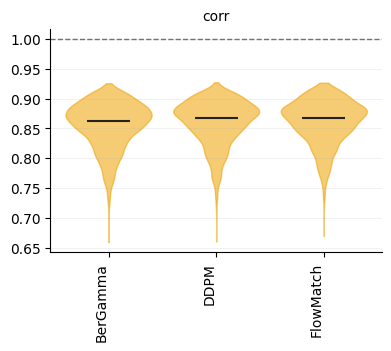

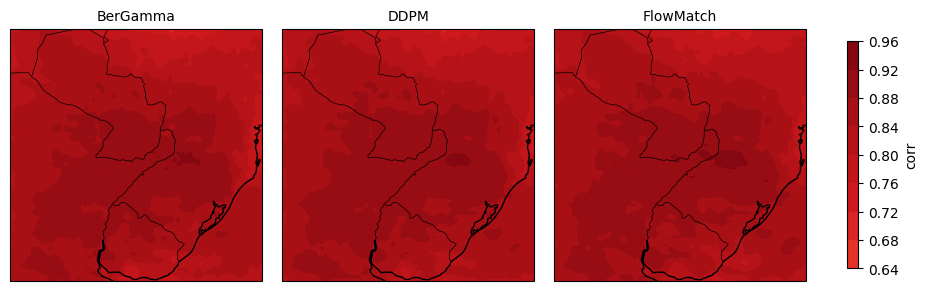

In [20]:
fig_violin, axes_violin = plot_metrics_violin(ds_metrics, ncols=2)
fig_violin.savefig(ROOT / "figures" / "cor_violin_plots.png", bbox_inches="tight", dpi=500)
plt.show()
fig_maps, axes_maps = plot_metrics_maps(ds_metrics)
fig_maps.savefig(ROOT / "figures" / "cor_maps.png", bbox_inches="tight", dpi=300)
plt.show()